# EPFL ML Project 1 — MICHD Risk Prediction

Main notebook: exploratory data analysis, feature processing, model training/evaluation and
submission generation. All required ML methods (`least_squares`, `ridge_regression`, ...) live
in `../implementations.py`, imported below as `impl` — that file is the one that gets graded, so
keep the canonical implementations there and just *call* them from here.

See `../project1_description.pdf` for the full project statement.

## 0. Setup

In [3]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")  # so we can import helpers.py / implementations.py from the repo root

import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data, create_csv_submission, load_csv_data_labels
import implementations as impl

DATA_DIR = "../data"

np.random.seed(1)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Load data

Requires `x_train.csv`, `y_train.csv`, `x_test.csv` in `../data/` — see `../data/README.md`.

In [4]:
x_labels = load_csv_data_labels(DATA_DIR)
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_DIR, sub_sample=True)

print(x_labels)
print("x_train:", x_train.shape)
print("x_test: ", x_test.shape)
print("y_train:", y_train.shape, "unique labels:", np.unique(y_train))

{0: '_STATE', 1: 'FMONTH', 2: 'IDATE', 3: 'IMONTH', 4: 'IDAY', 5: 'IYEAR', 6: 'DISPCODE', 7: 'SEQNO', 8: '_PSU', 9: 'CTELENUM', 10: 'PVTRESD1', 11: 'COLGHOUS', 12: 'STATERES', 13: 'CELLFON3', 14: 'LADULT', 15: 'NUMADULT', 16: 'NUMMEN', 17: 'NUMWOMEN', 18: 'CTELNUM1', 19: 'CELLFON2', 20: 'CADULT', 21: 'PVTRESD2', 22: 'CCLGHOUS', 23: 'CSTATE', 24: 'LANDLINE', 25: 'HHADULT', 26: 'GENHLTH', 27: 'PHYSHLTH', 28: 'MENTHLTH', 29: 'POORHLTH', 30: 'HLTHPLN1', 31: 'PERSDOC2', 32: 'MEDCOST', 33: 'CHECKUP1', 34: 'BPHIGH4', 35: 'BPMEDS', 36: 'BLOODCHO', 37: 'CHOLCHK', 38: 'TOLDHI2', 39: 'CVDSTRK3', 40: 'ASTHMA3', 41: 'ASTHNOW', 42: 'CHCSCNCR', 43: 'CHCOCNCR', 44: 'CHCCOPD1', 45: 'HAVARTH3', 46: 'ADDEPEV2', 47: 'CHCKIDNY', 48: 'DIABETE3', 49: 'DIABAGE2', 50: 'SEX', 51: 'MARITAL', 52: 'EDUCA', 53: 'RENTHOM1', 54: 'NUMHHOL2', 55: 'NUMPHON2', 56: 'CPDEMO1', 57: 'VETERAN3', 58: 'EMPLOY1', 59: 'CHILDREN', 60: 'INCOME2', 61: 'INTERNET', 62: 'WEIGHT2', 63: 'HEIGHT3', 64: 'PREGNANT', 65: 'QLACTLM2', 66: 'USE

In [5]:
def plot_top_values(title, data, N = 10, labels = None):
    labels = x_labels if labels is None else labels
    # N largest, NaN skipped
    valid_indices = np.flatnonzero(~np.isnan(data))
    top_indices = valid_indices[np.argsort(data[valid_indices])[::-1][:N]]

    top_labels = [labels[i] for i in top_indices]
    top_data = data[top_indices]

    plt.figure(figsize = (14, 4))
    plt.bar(top_labels, top_data)
    plt.xticks(rotation = 45, ha = "right")
    plt.xlabel("feature")
    plt.ylabel("value")
    plt.title(title)
    plt.tight_layout()
    plt.show()

## 2. Exploratory data analysis (raw data)

First look at the raw columns: identifier columns and class balance. Statistics on the features
(missing values, constant and correlated features, ...) are computed in section 3, on the preprocessed data.

In [10]:
# Find ID / date columns

import re

time_f = r'date|year|month|day|time'
indicator_f = r'code|phone|city|country|tel'
id_f = r'id|seq|state'

label_matcher = re.compile(".*(%s|%s|%s)" % (time_f, indicator_f, id_f),  re.I)

for label in x_labels.values():
    if label_matcher.match(label):
        print(label)

# Dates, IDs, phone screening
IDENTIFIER_COLUMNS = [
    "_STATE", "FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "DISPCODE",
    "SEQNO", "_PSU", "_STSTR",
    "CTELENUM", "CTELNUM1", "STATERES", "CSTATE",
]

def drop_columns_by_name(data, names, labels = None):
    labels = x_labels if labels is None else labels
    assert data.shape[1] == len(labels), "labels must describe the columns of data"
    kept_indices = [i for (i, name) in labels.items() if name not in names]
    return data[:, kept_indices]

_STATE
FMONTH
IDATE
IMONTH
IDAY
IYEAR
DISPCODE
SEQNO
CTELENUM
STATERES
CTELNUM1
CSTATE
CHCKIDNY
DECIDE
SMOKDAY2
ALCDAY5
VIDFCLT2
ARTTODAY
PSATIME
SCNTPAID
MSCODE
BEANDAY_
GRENDAY_
ORNGDAY_
_AIDTST3


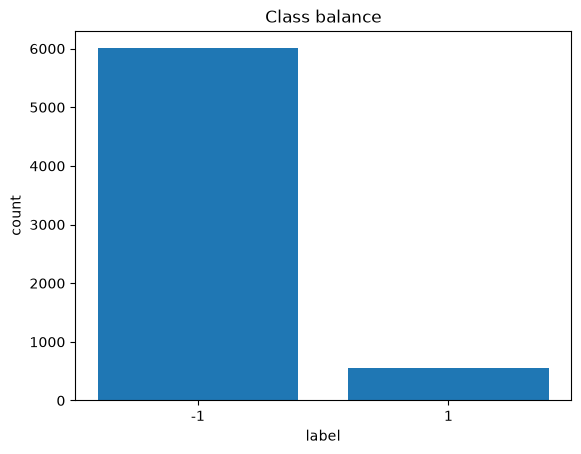

In [7]:
# TODO: class balance
labels, counts = np.unique(y_train, return_counts=True)
plt.bar(labels.astype(str), counts)
plt.xlabel("label")
plt.ylabel("count")
plt.title("Class balance")
plt.show()

## 3. Feature processing

1. Preprocessing: special codes and units -> plain numbers (normalization), then drop the identifier columns.
2. Statistics on the preprocessed data, which give the constant and correlated columns to drop.
3. `build_features`: everything combined. Must be applied identically to `x_train` and `x_test` —
   `run.py` has to reuse it exactly.

In [ ]:
# Normalization: codes, then units (see codebook.py)

from codebook import MISSING_CODES, NONE_CODES

column_index = {name: i for (i, name) in x_labels.items()}

def replace_codes(data, codes_per_column, new_value):
    data = data.copy()
    for name, codes in codes_per_column.items():
        j = column_index[name]
        data[np.isin(data[:, j], codes), j] = new_value
    return data

def normalize_missing_codes(data):
    """Don't know / refused -> NaN."""
    return replace_codes(data, MISSING_CODES, np.nan)

def normalize_none_codes(data):
    """None / never -> 0."""
    return replace_codes(data, NONE_CODES, 0)

def normalize_weight_to_kg(data):
    """WEIGHT2: pounds or 9xxx kg -> kg."""
    data = data.copy()
    w = data[:, column_index["WEIGHT2"]]
    kg = np.full(w.shape, np.nan)
    pounds, metric = (w >= 50) & (w <= 999), (w >= 9000) & (w <= 9998)
    kg[pounds] = w[pounds] * 0.45359237
    kg[metric] = w[metric] - 9000
    data[:, column_index["WEIGHT2"]] = kg
    return data

def normalize_height_to_cm(data):
    """HEIGHT3: ft/in (507) or 9xxx cm -> cm."""
    data = data.copy()
    h = data[:, column_index["HEIGHT3"]]
    feet, inches = h // 100, h % 100
    cm = np.full(h.shape, np.nan)
    imperial, metric = (h >= 200) & (h <= 711) & (inches < 12), (h >= 9000) & (h <= 9998)
    cm[imperial] = (feet[imperial] * 12 + inches[imperial]) * 2.54
    cm[metric] = h[metric] - 9000
    data[:, column_index["HEIGHT3"]] = cm
    return data

# First digit = unit -> days per unit (203 = 3 per week)
FREQUENCY_UNITS = {
    "ALCDAY5": {1: 7, 2: 30},
    "FRUITJU1": {1: 1, 2: 7, 3: 30}, "FRUIT1": {1: 1, 2: 7, 3: 30}, "FVBEANS": {1: 1, 2: 7, 3: 30},
    "FVGREEN": {1: 1, 2: 7, 3: 30}, "FVORANG": {1: 1, 2: 7, 3: 30}, "VEGETAB1": {1: 1, 2: 7, 3: 30},
    "EXEROFT1": {1: 7, 2: 30}, "EXEROFT2": {1: 7, 2: 30}, "STRENGTH": {1: 7, 2: 30},
    "BLDSUGAR": {1: 1, 2: 7, 3: 30, 4: 365}, "FEETCHK2": {1: 1, 2: 7, 3: 30, 4: 365},
}

def normalize_frequency_to_per_day(data):
    """Frequencies -> times per day."""
    data = data.copy()
    for name, days_per_unit in FREQUENCY_UNITS.items():
        j = column_index[name]
        v = data[:, j]
        per_day = np.full(v.shape, np.nan)
        per_day[v == 0] = 0
        for unit, days in days_per_unit.items():
            in_unit = (v // 100) == unit
            per_day[in_unit] = (v[in_unit] % 100) / days
        data[:, j] = per_day
    return data

def normalize_duration_to_days(data):
    """LONGWTCH -> days."""
    data = data.copy()
    j = column_index["LONGWTCH"]
    v = data[:, j]
    days = np.full(v.shape, np.nan)
    for unit, days_per_unit in {1: 1, 2: 7, 3: 30, 4: 365}.items():
        in_unit = (v // 100) == unit
        days[in_unit] = (v[in_unit] % 100) * days_per_unit
    data[:, j] = days
    return data

def normalize_hours_minutes_to_minutes(data):
    """EXERHMM1/2: 130 = 1h30 -> minutes."""
    data = data.copy()
    for name in ["EXERHMM1", "EXERHMM2"]:
        v = data[:, column_index[name]]
        data[:, column_index[name]] = (v // 100) * 60 + v % 100
    return data

def normalize_month_year_to_year(data):
    """FLSHTMY2, HIVTSTD3: 32015 = March 2015 -> 2015.21."""
    data = data.copy()
    for name in ["FLSHTMY2", "HIVTSTD3"]:
        v = data[:, column_index[name]]
        month, year = v // 10000, v % 10000
        year_fraction = np.where(month == 77, 0.5, (month - 0.5) / 12)
        valid = ((month <= 12) | (month == 77)) & (year >= 1985) & (year <= 2016)
        data[:, column_index[name]] = np.where(valid, year + year_fraction, np.nan)
    return data

def normalize_codes(data):
    """Codes first, then units."""
    data = normalize_missing_codes(data)
    data = normalize_none_codes(data)
    data = normalize_weight_to_kg(data)
    data = normalize_height_to_cm(data)
    data = normalize_frequency_to_per_day(data)
    data = normalize_duration_to_days(data)
    data = normalize_hours_minutes_to_minutes(data)
    data = normalize_month_year_to_year(data)
    return data

def normalize_nan(data, mean_per_feature = None):
    """NaN -> column mean (pass train means for x_test)."""
    if mean_per_feature is None:
        mean_per_feature = np.nanmean(data, axis=0)

    new_data = data.copy()
    row, col = np.where(np.isnan(data))
    new_data[row, col] = mean_per_feature[col]

    return new_data

In [ ]:
# Preprocessing: normalize, drop identifiers

def preprocess(x):
    return drop_columns_by_name(normalize_codes(x), IDENTIFIER_COLUMNS)

# Index -> name after preprocessing
preprocessed_labels = dict(enumerate(name for name in x_labels.values() if name not in IDENTIFIER_COLUMNS))

x_train_preprocessed = preprocess(x_train)
print("x_train_preprocessed:", x_train_preprocessed.shape)

### Statistics on the preprocessed data

In [ ]:
# NaN ratio

nan_ratio_per_feature = np.isnan(x_train_preprocessed).mean(axis=0)
plot_top_values("NaN ratio / feature", nan_ratio_per_feature, N=50, labels=preprocessed_labels)

In [ ]:
# Constant features (NaN ignored)

def top_value_ratio(column):
    values = column[~np.isnan(column)]
    return np.unique(values, return_counts=True)[1].max() / values.size if values.size else np.nan

top_value_ratio_per_feature = np.array([top_value_ratio(column) for column in x_train_preprocessed.T])
plot_top_values("Top value ratio (non-NaN) / feature", top_value_ratio_per_feature, N=50, labels=preprocessed_labels)

# 0.95 would drop real conditions (CVDSTRK3)
CONSTANT_THRESHOLD = 0.99

CONSTANT_COLUMNS = [preprocessed_labels[j] for j in np.flatnonzero(top_value_ratio_per_feature >= CONSTANT_THRESHOLD)]
print(len(CONSTANT_COLUMNS), "constant columns:", CONSTANT_COLUMNS)

In [ ]:
# |Correlation| feature - output

MIN_ROWS = 100  # fewer rows = noise

def output_correlation(column):
    m = ~np.isnan(column)
    if m.sum() < MIN_ROWS or np.std(column[m]) == 0 or np.std(y_train[m]) == 0:
        return np.nan
    return abs(np.corrcoef(column[m], y_train[m])[0, 1])

output_correlation_per_feature = np.array([output_correlation(column) for column in x_train_preprocessed.T])
plot_top_values("|Correlation| feature - output", output_correlation_per_feature, N=50, labels=preprocessed_labels)

In [ ]:
# Distinct values

unique_values_per_feature = np.array([np.unique(column).size for column in x_train_preprocessed.T])
plot_top_values("Distinct values / feature", unique_values_per_feature, N=50, labels=preprocessed_labels)

In [ ]:
# Outlier ratio (robust z > 3.5, MAD = 0 skipped)

median = np.nanmedian(x_train_preprocessed, axis=0)
mad = np.nanmedian(np.abs(x_train_preprocessed - median), axis=0)
with np.errstate(divide="ignore", invalid="ignore"):
    robust_z = 0.6745 * (x_train_preprocessed - median) / mad

outlier_ratio_per_feature = np.where(mad > 0, (np.abs(robust_z) > 3.5).mean(axis=0), np.nan)
plot_top_values("Outlier ratio / feature", outlier_ratio_per_feature, N=50, labels=preprocessed_labels)

In [ ]:
# |Correlation| feature - feature

with np.errstate(divide="ignore", invalid="ignore"):
    feature_correlation = np.abs(np.corrcoef(normalize_nan(x_train_preprocessed), rowvar=False))

# Pairs i < j
pair_i, pair_j = np.triu_indices(x_train_preprocessed.shape[1], k=1)
pair_correlation = feature_correlation[pair_i, pair_j]
pair_labels = [f"{preprocessed_labels[i]} × {preprocessed_labels[j]}" for i, j in zip(pair_i, pair_j)]
plot_top_values("|Correlation| feature - feature", pair_correlation, N=100, labels=pair_labels)

# 0.8 would drop distinct features (_BMI5)
CORRELATION_THRESHOLD = 0.95

# Per pair, drop the one less correlated with the output
output_correlation_or_zero = np.nan_to_num(output_correlation_per_feature)
correlated_indices = set()
for k in np.argsort(np.nan_to_num(pair_correlation))[::-1]:
    if not pair_correlation[k] >= CORRELATION_THRESHOLD:
        break
    i, j = pair_i[k], pair_j[k]
    if i in correlated_indices or j in correlated_indices:
        continue
    correlated_indices.add(i if output_correlation_or_zero[i] < output_correlation_or_zero[j] else j)

CORRELATED_COLUMNS = [preprocessed_labels[j] for j in sorted(correlated_indices)]
print(len(CORRELATED_COLUMNS), "correlated columns:", CORRELATED_COLUMNS)

In [ ]:
# Drop constant + correlated
def filter_columns(data):
    return drop_columns_by_name(data, CONSTANT_COLUMNS + CORRELATED_COLUMNS, labels=preprocessed_labels)

# Train statistics, reused for x_test
x_train_filtered = filter_columns(x_train_preprocessed)
TRAIN_MEAN = np.nan_to_num(np.nanmean(x_train_filtered, axis=0), nan=0.0)
TRAIN_STD = np.nan_to_num(np.nanstd(x_train_filtered, axis=0), nan=1.0)
TRAIN_STD[TRAIN_STD == 0] = 1.0

def standardize(data):
    return (data - TRAIN_MEAN) / TRAIN_STD

def build_features(x_preprocessed):
    """Filter, fill NaN, standardize, add bias."""
    data = filter_columns(x_preprocessed)
    data = normalize_nan(data, TRAIN_MEAN)
    data = standardize(data)
    
    return np.c_[np.ones(data.shape[0]), data]


In [ ]:
tx_train = build_features(x_train_preprocessed)
tx_test = build_features(preprocess(x_test))
# y_train_processed = build_labels(y_train)

print("tx_train:", tx_train.shape, "tx_test:", tx_test.shape)

## 4. Train / validation split (local evaluation)

Always estimate test error locally (holdout or k-fold CV) — AIcrowd only allows 5
submissions/day and the competition score must not be your only signal.

In [ ]:
def split_data(y, tx, ratio=0.8, seed=1):
    """Random train/validation split."""
    # TODO: implement (np.random.permutation, slice by ratio)
    raise NotImplementedError


def build_k_indices(y, k_fold, seed=1):
    """Build k-fold row indices for cross-validation."""
    # TODO: implement
    raise NotImplementedError

## 5. Baselines: the 6 required methods

Sanity-check each function in `implementations.py` on the processed data before trying
anything fancier. These are also what the course's grading tests exercise directly.

In [ ]:
# Example calls once build_features / split_data are implemented:
#
# w, loss = impl.least_squares(y_tr, tx_tr)
# w, loss = impl.ridge_regression(y_tr, tx_tr, lambda_=1e-3)
# w, loss = impl.mean_squared_error_gd(y_tr, tx_tr, initial_w, max_iters=100, gamma=0.1)
# w, loss = impl.mean_squared_error_sgd(y_tr, tx_tr, initial_w, max_iters=1000, gamma=0.01)
# w, loss = impl.logistic_regression(y_tr01, tx_tr, initial_w, max_iters=100, gamma=0.1)
# w, loss = impl.reg_logistic_regression(y_tr01, tx_tr, lambda_=1e-3, initial_w=initial_w, max_iters=100, gamma=0.1)

## 6. Model selection

Hyperparameter search (e.g. lambda_, gamma) via cross-validation. Keep track of results for
the ablation study required in the report.

In [ ]:
# TODO: cross-validation loop over hyperparameters, record train/val loss and a
# classification metric (accuracy / F1 — the labels are imbalanced).

## 7. Final model + submission

This should mirror exactly what `../run.py` does, so the two stay reproducible together.

In [ ]:
# w, loss = impl.ridge_regression(y_train_processed, tx_train, lambda_=...)
# y_pred = tx_test @ w
# y_pred = np.where(y_pred >= 0, 1, -1)
# create_csv_submission(test_ids, y_pred, "../submission.csv")